In [1]:

from langgraph.graph import MessagesState
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage
from langgraph.graph import StateGraph, START,END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI
import os

In [2]:
load_dotenv()

True

In [3]:
google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError("GOOGLE_API_KEY is missing")

postgres_uri = os.getenv("POSTGRES_URI")
if not postgres_uri:
    raise ValueError("POSTGRES_URI is missing")

In [4]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

In [5]:
def chat(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

In [6]:
def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}

    return {}

In [7]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", chat)
builder.add_node("delete_old_messages", delete_old_messages)

In [8]:
builder.add_edge(START, "call_model")
builder.add_edge("call_model", "delete_old_messages")
builder.add_edge("delete_old_messages", END)

In [9]:
graph = builder.compile(checkpointer = InMemorySaver())

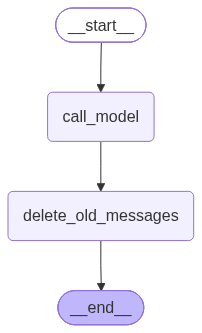

In [10]:
graph

In [11]:
config = {"configurable": {"thread_id": "t1"}}

In [12]:
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Nitish"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Langchain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Quantum Mechanics"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='09483389-f201-4c0e-b235-681e8cd93492'),
  AIMessage(content=[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to help developers build applications powered by Large Language Models (LLMs). \n\nIf LLMs (like OpenAI\'s GPT-4, Claude, or Llama) are the "brains," **LangChain is the toolkit and glue** that connects those brains to real-world data, tools, APIs, and custom software logic.\n\n---\n\n### 1. The Problem LangChain Solves\n\nCalling an LLM API directly is simple. However, building a *real-world production application* requires a lot of extra work:\n* How do you give the LLM access to your private PDFs or databases?\n* How do you chain multiple LLM calls together?\n* How do you switch from OpenAI to Anthropic without rewriting your whole codebase?\n* How do you formatted outputs (like forcing an LLM to return valid JSON)?\n\nLangChain provides standard

In [13]:
snap = graph.get_state(config)

In [14]:
snap

StateSnapshot(values={'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='09483389-f201-4c0e-b235-681e8cd93492'), AIMessage(content=[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to help developers build applications powered by Large Language Models (LLMs). \n\nIf LLMs (like OpenAI\'s GPT-4, Claude, or Llama) are the "brains," **LangChain is the toolkit and glue** that connects those brains to real-world data, tools, APIs, and custom software logic.\n\n---\n\n### 1. The Problem LangChain Solves\n\nCalling an LLM API directly is simple. However, building a *real-world production application* requires a lot of extra work:\n* How do you give the LLM access to your private PDFs or databases?\n* How do you chain multiple LLM calls together?\n* How do you switch from OpenAI to Anthropic without rewriting your whole codebase?\n* How do you formatted outputs (like forcing an LLM to return valid JSON)?\n\nLangChai

In [16]:
snap.values

{'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='09483389-f201-4c0e-b235-681e8cd93492'),
  AIMessage(content=[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to help developers build applications powered by Large Language Models (LLMs). \n\nIf LLMs (like OpenAI\'s GPT-4, Claude, or Llama) are the "brains," **LangChain is the toolkit and glue** that connects those brains to real-world data, tools, APIs, and custom software logic.\n\n---\n\n### 1. The Problem LangChain Solves\n\nCalling an LLM API directly is simple. However, building a *real-world production application* requires a lot of extra work:\n* How do you give the LLM access to your private PDFs or databases?\n* How do you chain multiple LLM calls together?\n* How do you switch from OpenAI to Anthropic without rewriting your whole codebase?\n* How do you formatted outputs (like forcing an LLM to return valid JSON)?\n\nLangChain provides standard

In [17]:
d = snap.values

In [19]:
d["messages"]

[HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='09483389-f201-4c0e-b235-681e8cd93492'),
 AIMessage(content=[{'type': 'text', 'text': '**LangChain** is an open-source framework designed to help developers build applications powered by Large Language Models (LLMs). \n\nIf LLMs (like OpenAI\'s GPT-4, Claude, or Llama) are the "brains," **LangChain is the toolkit and glue** that connects those brains to real-world data, tools, APIs, and custom software logic.\n\n---\n\n### 1. The Problem LangChain Solves\n\nCalling an LLM API directly is simple. However, building a *real-world production application* requires a lot of extra work:\n* How do you give the LLM access to your private PDFs or databases?\n* How do you chain multiple LLM calls together?\n* How do you switch from OpenAI to Anthropic without rewriting your whole codebase?\n* How do you formatted outputs (like forcing an LLM to return valid JSON)?\n\nLangChain provides standardized "Lego bri

In [15]:
print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 8
